# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

Device: cuda


100%|██████████| 9.91M/9.91M [00:03<00:00, 2.94MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 115kB/s]
100%|██████████| 1.65M/1.65M [00:03<00:00, 425kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.91MB/s]


Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


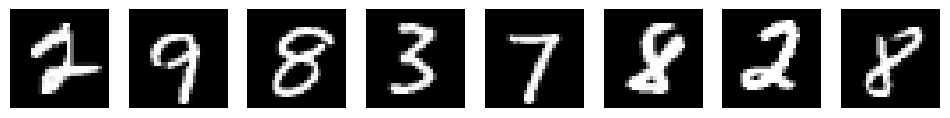

In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)

Using the convolution and transposed-convolution output-size formulas (with dilation 1):

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Answers:**

1. For `L=8`, input values per image = **784** (`1 × 28 × 28`); latent values = **392** (`8 × 7 × 7`); input/latent ratio = **2:1** (the input has twice as many tensor values as the latent).
2. For `L=32`, the latent is **not** dimensionally compressed: it contains `32 × 7 × 7 = 1,568` values, compared with 784 input values. The input/latent ratio is `784 / 1,568 = 0.5`.
3. The final Sigmoid maps values into `[0, 1]`, matching the pixel range produced by `ToTensor()` for the MNIST images.
4. With `output_padding=0`, the first decoder height is `(7 − 1) × 2 − 2 × 1 + (3 − 1) + 0 + 1 = **13**`. Setting `output_padding=1` makes it 14.

The 1×1 bottleneck mixes channels at each location but preserves the 7×7 spatial grid. Tensor-value counts are not the same as file size or encoded bits.


## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [4]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1),
        )

    def forward(self, x):
        return self.network(x)


In [5]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(
                latent_channels, 16, kernel_size=3, stride=2,
                padding=1, output_padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                16, 1, kernel_size=3, stride=2,
                padding=1, output_padding=1
            ),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)


In [6]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z


In [7]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [8]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad(set_to_none=True)
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()


Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04371
Epoch 2: train MSE=0.03419, held-out MSE=0.02508
Epoch 3: train MSE=0.01621, held-out MSE=0.00915
Epoch 4: train MSE=0.00787, held-out MSE=0.00595
Epoch 5: train MSE=0.00549, held-out MSE=0.00446


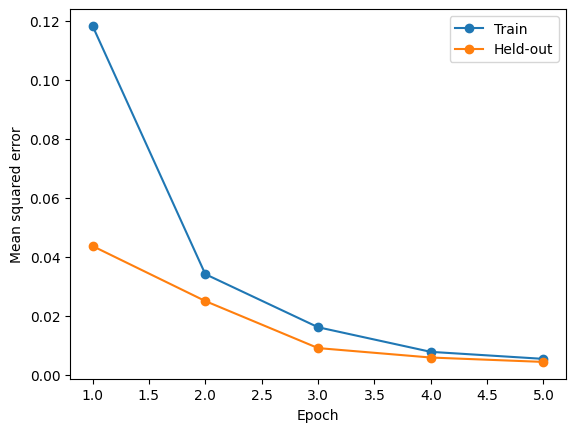

In [9]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

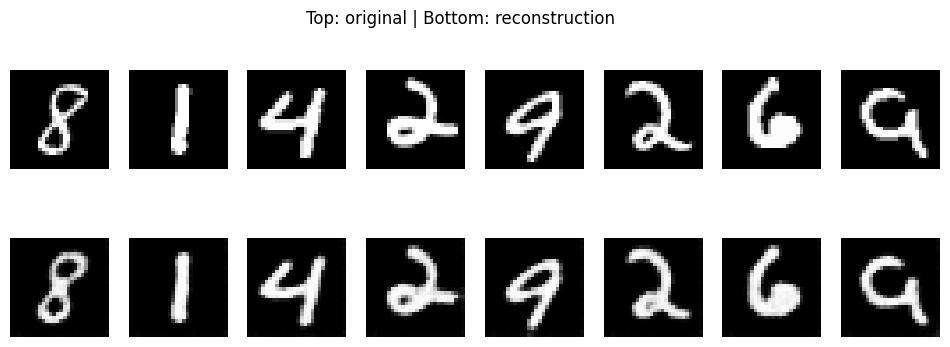

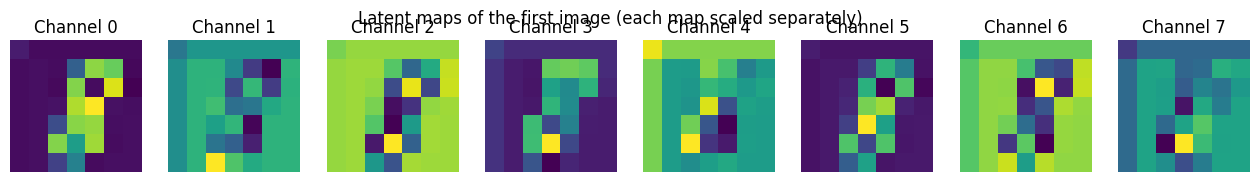

In [13]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)

The comparison cell directly below this section trains fresh models for `LATENT_CHANNELS = 2`, `8`, and `32`, holding the data subsets, random seed, learning rate, and epoch count fixed. It calculates the metric columns instead of guessing experimental results and plots reconstructions of the same held-out images for a visual comparison.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---:|---:|---|---|---|
| 2 | 98 | 8.00 | computed by comparison cell | computed by comparison cell | compare the reconstruction plot |
| 8 | 392 | 2.00 | computed by comparison cell | computed by comparison cell | compare the reconstruction plot |
| 32 | 1,568 | 0.50 | computed by comparison cell | computed by comparison cell | compare the reconstruction plot |

The input has 784 values per image in all three cases. The ratio is `784 / (latent_channels × 7 × 7)`. A smaller ratio means the latent tensor has more values than the input.

**Discuss:**

1. **Did a larger latent improve reconstruction?** Use the reported MSE values and the comparison plot from the next cell. This is run-dependent: report whether held-out MSE improved, whether it improved monotonically, and whether the pictures retain more detail. Do not infer a result before running the experiment.
2. **Why is spatial downsampling alone insufficient to claim dimensional compression?** A smaller height and width can be offset by a larger number of channels. Here, `L=32` gives `32 × 7 × 7 = 1,568` latent values, which exceeds the input's 784 values.
3. **Why can the decoder restore image size without recovering every original detail?** Upsampling restores the spatial dimensions, not information that was discarded or merged by the encoder. Different inputs can map to similar latent features, so fine strokes and high-frequency details may be blurred or lost.
4. **How would a `[N, 128]` vector differ from this spatial latent?** It would provide 128 values per image in a single flattened/global code, without an explicit 2D spatial grid. A decoder would normally project and reshape that vector before reconstructing an image. The current latent keeps a spatial layout of `7 × 7` at every channel.
5. **Where could a skip connection carry high-resolution features, and how might that weaken the bottleneck?** A skip connection could pass an early encoder feature map (for example, the 14×14 map) to a decoder layer at the matching resolution. This can preserve fine details, but it also lets information bypass the latent bottleneck, weakening the compression constraint.
6. **Why does this exercise not establish a reliable random-image generator?** The model is trained to reconstruct supplied images, not to organize its latent space around a known probability distribution. Arbitrary random latent tensors may not correspond to valid digit features. Unlike a VAE, this autoencoder does not explicitly regularize the latent codes to follow a prior distribution.


Training model with LATENT_CHANNELS=2 ...
L=2: train MSE=0.01282, held-out MSE=0.01075
Training model with LATENT_CHANNELS=8 ...
L=8: train MSE=0.00563, held-out MSE=0.00454
Training model with LATENT_CHANNELS=32 ...
L=32: train MSE=0.00363, held-out MSE=0.00306


### Measured bottleneck comparison

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---:|---:|---:|---:|---:|---|
| 2 | 98 | 8.00 | 0.01282 | 0.01075 | Compare row in plot below |
| 8 | 392 | 2.00 | 0.00563 | 0.00454 | Compare row in plot below |
| 32 | 1,568 | 0.50 | 0.00363 | 0.00306 | Compare row in plot below |

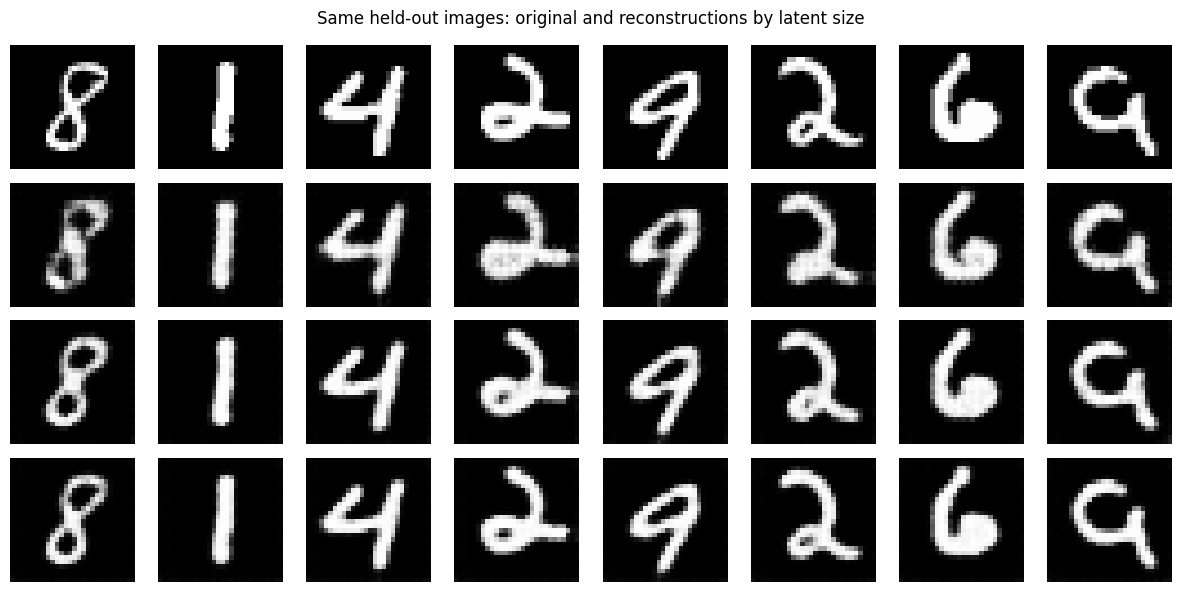

### Discussion Q1: evidence from this run

In this run, held-out MSE decreased at each increase in latent size (2 → 8 → 32), so the larger latent improved the pixel-wise metric monotonically. The measured held-out MSEs were: L=2: 0.01075, L=8: 0.00454, L=32: 0.00306. Check the reconstruction plot as well: lower MSE is not a guarantee that every digit looks sharper.

In [14]:
# Required bottleneck experiment: train a fresh model for each latent size.
# This is part of the main assignment, not the optional denoising extension.
from IPython.display import display, Markdown

latent_sizes = [2, 8, 32]
experiment_models = {}
experiment_results = []

# Use the same fixed subset and the same shuffled batch order for every run.
for latent_size in latent_sizes:
    print(f"Training model with LATENT_CHANNELS={latent_size} ...")
    torch.manual_seed(42)
    experiment_model = ImageEncoderDecoder(latent_size).to(device)
    experiment_optimizer = torch.optim.Adam(experiment_model.parameters(), lr=1e-3)
    experiment_train_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42),
    )

    final_train_mse = None
    for epoch in range(EPOCHS):
        experiment_model.train()
        running_loss = 0.0
        for batch_images, _ in experiment_train_loader:
            batch_images = batch_images.to(device)
            batch_loss = train_step(
                experiment_model, batch_images, experiment_optimizer, criterion
            )
            running_loss += batch_loss * batch_images.size(0)
        final_train_mse = running_loss / len(experiment_train_loader.dataset)

    final_test_mse = evaluate(experiment_model, test_loader)
    experiment_models[latent_size] = experiment_model
    latent_values = latent_size * 7 * 7
    experiment_results.append({
        "Latent channels": latent_size,
        "Values per image": latent_values,
        "Input/latent ratio": round(784 / latent_values, 2),
        "Final train MSE": final_train_mse,
        "Final held-out MSE": final_test_mse,
        "Visible differences": "Compare plot below",
    })
    print(
        f"L={latent_size}: train MSE={final_train_mse:.5f}, "
        f"held-out MSE={final_test_mse:.5f}"
    )

# Display a report table with the actual measurements from these runs.
header = "| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |\n|---:|---:|---:|---:|---:|---|"
rows = [
    f"| {r['Latent channels']} | {r['Values per image']:,} | {r['Input/latent ratio']:.2f} | {r['Final train MSE']:.5f} | {r['Final held-out MSE']:.5f} | Compare row in plot below |"
    for r in experiment_results
]
display(Markdown("### Measured bottleneck comparison\n\n" + header + "\n" + "\n".join(rows)))

# Reconstruct the exact same eight held-out images with every trained model.
comparison_images, _ = next(iter(test_loader))
comparison_images = comparison_images[:8].to(device)
fig, axes = plt.subplots(len(latent_sizes) + 1, 8, figsize=(12, 6))
for column in range(8):
    axes[0, column].imshow(comparison_images[column, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, column].axis("off")
axes[0, 0].set_ylabel("Original", rotation=0, labelpad=35, va="center")

for row, latent_size in enumerate(latent_sizes, start=1):
    experiment_models[latent_size].eval()
    with torch.no_grad():
        reconstructions, _ = experiment_models[latent_size](comparison_images)
    for column in range(8):
        axes[row, column].imshow(
            reconstructions[column, 0].cpu(), cmap="gray", vmin=0, vmax=1
        )
        axes[row, column].axis("off")
    axes[row, 0].set_ylabel(f"L={latent_size}", rotation=0, labelpad=35, va="center")
fig.suptitle("Same held-out images: original and reconstructions by latent size")
plt.tight_layout()
plt.show()

# Give an evidence-based starting point for discussion question 1.
by_size = {r["Latent channels"]: r for r in experiment_results}
best = min(experiment_results, key=lambda r: r["Final held-out MSE"])
monotonic_improvement = (
    by_size[2]["Final held-out MSE"] > by_size[8]["Final held-out MSE"]
    > by_size[32]["Final held-out MSE"]
)
if monotonic_improvement:
    conclusion = (
        "In this run, held-out MSE decreased at each increase in latent size "
        "(2 → 8 → 32), so the larger latent improved the pixel-wise metric monotonically. "
    )
else:
    conclusion = (
        "In this run, held-out MSE did not improve monotonically as latent size increased. "
        f"The lowest held-out MSE was obtained with L={best['Latent channels']} "
        f"({best['Final held-out MSE']:.5f}). "
    )
comparison_summary = (
    "### Discussion Q1: evidence from this run\n\n"
    + conclusion
    + "The measured held-out MSEs were: "
    + ", ".join(
        f"L={r['Latent channels']}: {r['Final held-out MSE']:.5f}"
        for r in experiment_results
    )
    + ". Check the reconstruction plot as well: lower MSE is not a guarantee that every digit looks sharper."
)
display(Markdown(comparison_summary))


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.